<a href="https://colab.research.google.com/github/Angela-Benedict/ds2002-fa26/blob/main/notebooks/walmart-hurricane-project/notebooks/scratch" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Question 4: Store-Level Geographic Patterns
Do all Florida store locations experience the same surge patterns, or do stores closer to the predicted hurricane path show earlier and larger spikes? Identify any stores that appear to be outliers.

Requires: Joining store location data with transactions, geographic grouping, comparing surge timing and magnitude across stores, bar chart or grouped comparison, outlier identification.

In [34]:
!git clone https://github.com/Angela-Benedict/ds2002-fa26.git

fatal: destination path 'ds2002-fa26' already exists and is not an empty directory.


In [35]:
#1 cleaned data:
import pandas as pd

sales = pd.read_csv(
    "ds2002-fa26/notebooks/walmart-hurricane-project/data/walmart_transactions.csv"
)
q1 = sales.drop_duplicates().copy()

q1["timestamp"] = pd.to_datetime(q1["timestamp"], format="mixed", errors="coerce")
q1["date"] = q1["timestamp"].dt.normalize()
q1["quantity"] = pd.to_numeric(q1["quantity"], errors= "coerce")

q1['category_clean'] = (
    q1["category"]
    .astype(str)
    .str.strip()
    .str.lower()
)

category_map = {
    "emergency": "Emergency Supplies",
    'emergency supplies': "Emergency Supplies",
    "groceries": "Groceries",
    "grocery": "Groceries",
    "electronics": "Electronics",
    "household": "Household",
    "household essentials": "Household",
    "baby": "Baby Products",
    "baby products": "Baby Products",
    "breakfast": "Breakfast Foods",
    "breakfast foods":"Breakfast Foods",
    "health":"Health",
    "health & wellness":"Health",
    "alcohol":"Alcohol",
    "alcoholic beverages":"Alcohol",
    'games & entertainment':"Entertainment",
    "entertainment":"Entertainment",
    "snacks":"Snacks"
}
q1["category_clean"] = q1["category_clean"].map(category_map)

# Clean store IDs - NEEDS TO BE ADDED TO Q1
q1["store_id"] = (
    q1["store_id"]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.replace("-", "", regex=False)
    .str.replace("_", "", regex=False)
)

daily_category = (
    q1.groupby(["date", "category_clean"]) ["quantity"]
    .sum()
    .reset_index()
)

In [36]:
#2Nothing needs to be transfered
landfall = pd.Timestamp("2024-9-26")

baseline = daily_category[
    (daily_category["date"] >= "2024-9-08") &
    (daily_category["date"] <= "2024-9-15")
]
surge = daily_category[
    (daily_category["date"] >= "2024-9-19") &
    (daily_category["date"] <= "2024-9-25")
]

baseline_avg = baseline.groupby("category_clean")["quantity"].mean()
surge_avg = surge.groupby("category_clean")["quantity"].mean()
surge_multiple = surge_avg / baseline_avg

percent_increase = (surge_multiple - 1) * 100

q1_results = pd.DataFrame({
    "baseline_avg": baseline_avg,
    "pre_landfall_avg": surge_avg,
    "surge_multiple": surge_multiple,
    "percent_increase": percent_increase
}).sort_values("percent_increase", ascending=False)

daily_wide=daily_category.pivot(
    index='date',
    columns='category_clean',
    values = 'quantity'
)

q1_results.round(2)

,baseline_avg,pre_landfall_avg,surge_multiple,percent_increase
category_clean,,,,
Breakfast Foods,72.75,375.71,5.16,416.45
Emergency Supplies,350.62,1002.29,2.86,185.86
Electronics,69.62,175.29,2.52,151.76
Alcohol,59.25,138.29,2.33,133.39
Health,40.62,94.14,2.32,131.74
Entertainment,101.88,227.00,2.23,122.82
Household,83.75,175.86,2.10,109.98
Groceries,169.25,305.29,1.80,80.38
Baby Products,85.50,132.57,1.55,55.05


In [37]:
#3 Calculate daily sales by store: NEEDS TO BE ADDED TO Q3
daily_store = (
    q1.groupby(["date", "store_id"])["quantity"]
    .sum()
    .reset_index()
)

# Separate baseline and surge periods
baseline_store = daily_store[
    (daily_store["date"] >= "2024-09-08") &
    (daily_store["date"] <= "2024-09-15")
]

surge_store = daily_store[
    (daily_store["date"] >= "2024-09-19") &
    (daily_store["date"] <= "2024-09-25")
]

# Calculate average daily sales for each store
baseline_avg = baseline_store.groupby("store_id")["quantity"].mean()
surge_avg = surge_store.groupby("store_id")["quantity"].mean()

# Calculate surge multiple
surge_multiple = surge_avg / baseline_avg
percent_increase = (surge_multiple - 1) * 100

# Create store results
store_results = pd.DataFrame({
    "baseline_avg": baseline_avg,
    "pre_landfall_avg": surge_avg,
    "surge_multiple": surge_multiple,
    "percent_increase": percent_increase
}).sort_values("percent_increase", ascending=False)

store_results = store_results.reset_index()

# Calculate total transactions/quantity for each store
total_store_sales = (
    q1.groupby("store_id")["quantity"]
    .sum()
    .reset_index(name="total_transactions")
)

# Display every store's surge multiple
display(store_results.round(2))

,store_id,baseline_avg,pre_landfall_avg,surge_multiple,percent_increase
0,FL330,83.38,235.14,2.82,182.03
1,FL619,80.75,222.43,2.75,175.45
2,FL105,90.88,231.29,2.55,154.51
3,FL710,90.25,226.43,2.51,150.89
4,FL445,93.62,231.43,2.47,147.19
5,FL412,89.62,221.43,2.47,147.06
6,FL302,97.62,239.29,2.45,145.11
7,FL287,89.50,218.71,2.44,144.37
8,FL156,95.25,228.57,2.40,139.97
9,FL078,93.00,217.00,2.33,133.33


In [38]:
#4 Store ID: NEEDS TO BE ADDED TO Q3
import pandas as pd, numpy as np, matplotlib.pyplot as plt

stores = pd.read_csv(
    "ds2002-fa26/notebooks/walmart-hurricane-project/data/store_locations.csv"
)

# Clean store IDs
stores["store_id"] = (
    stores["store_id"]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.replace("-", "", regex=False)
    .str.replace("_", "", regex=False)
)
stores = stores.drop_duplicates().copy()

stores

,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL287,Walmart Neighborhood Market Kissimmee,Kissimmee,Florida,34741,28.2920,-81.4076,Central
5,FL156,Walmart Supercenter Daytona Beach,Daytona Beach,FL,32114,29.2108,-81.0228,East
6,FL501,Walmart Supercenter Fort Myers,Fort Myers,FL,33901,26.6406,-81.8723,West
7,FL078,Walmart Supercenter Gainesville,Gainesville,FL,32601,29.6516,-82.3248,North
8,FL619,Walmart Supercenter Tallahassee,Tallahassee,FL,32301,NaN,NaN,Panhandle
9,FL445,Walmart Supercenter St. Petersburg,St. Petersburg,Fla.,33701,27.7676,-82.6403,West


In [39]:
#5 JOIN store results with store locations and total transactions: NEEDS TO BE ADDED TO Q3
store_results = store_results.merge(
    stores[["store_id", "latitude", "longitude", "region"]],
    on="store_id",
    how="left"
)

store_results = store_results.merge(        #merges total_transactions into df
    total_store_sales,
    on="store_id",
    how="left"
)

# Update the store's coordinates
store_results.loc[store_results["store_id"] == "FL619", "latitude"] = 30.4383
store_results.loc[store_results["store_id"] == "FL619", "longitude"] = -84.2807

display(store_results)

,store_id,baseline_avg,pre_landfall_avg,surge_multiple,percent_increase,latitude,longitude,region,total_transactions
0,FL330,83.375,235.142857,2.820304,182.030413,25.7617,-80.1918,South,4195
1,FL619,80.750,222.428571,2.754533,175.453339,30.4383,-84.2807,Panhandle,4003
2,FL105,90.875,231.285714,2.545097,154.509727,27.9506,-82.4572,West,4152
3,FL710,90.250,226.428571,2.508904,150.890384,30.4213,-87.2169,Panhandle,4119
4,FL445,93.625,231.428571,2.471867,147.186725,27.7676,-82.6403,West,4253
5,FL412,89.625,221.428571,2.470612,147.061168,30.3322,-81.6557,North,4077
6,FL302,97.625,239.285714,2.451070,145.107006,28.0395,-81.9498,Central,4257
7,FL287,89.500,218.714286,2.443735,144.373504,28.2920,-81.4076,Central,4057
8,FL156,95.250,228.571429,2.399700,139.970004,29.2108,-81.0228,East,4187
9,FL078,93.000,217.000000,2.333333,133.333333,29.6516,-82.3248,North,4027


In [40]:
# #6 Calculate distance from a specific latitude and longitude

import numpy as np

# Set reference location
reference_lat = 30.0
reference_long = -83.7

# Haversine distance function
def calculate_distance(lat1, lon1, lat2, lon2):
    earth_radius = 3958.8  # Earth radius in miles

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

    return earth_radius * c


# Calculate distance for every store
store_results["miles_from_landfall"] = calculate_distance(
    reference_lat,
    reference_long,
    store_results["latitude"].astype(float),
    store_results["longitude"].astype(float)
)

# Display results
display(store_results.round(2))

,store_id,baseline_avg,pre_landfall_avg,surge_multiple,percent_increase,latitude,longitude,region,total_transactions,miles_from_landfall
0,FL330,83.38,235.14,2.82,182.03,25.76,-80.19,South,4195,362.80
1,FL619,80.75,222.43,2.75,175.45,30.44,-84.28,Panhandle,4003,46.03
2,FL105,90.88,231.29,2.55,154.51,27.95,-82.46,West,4152,160.29
3,FL710,90.25,226.43,2.51,150.89,30.42,-87.22,Panhandle,4119,211.99
4,FL445,93.62,231.43,2.47,147.19,27.77,-82.64,West,4253,167.04
5,FL412,89.62,221.43,2.47,147.06,30.33,-81.66,North,4077,124.26
6,FL302,97.62,239.29,2.45,145.11,28.04,-81.95,Central,4257,171.84
7,FL287,89.50,218.71,2.44,144.37,28.29,-81.41,Central,4057,181.83
8,FL156,95.25,228.57,2.40,139.97,29.21,-81.02,East,4187,169.82
9,FL078,93.00,217.00,2.33,133.33,29.65,-82.32,North,4027,85.87


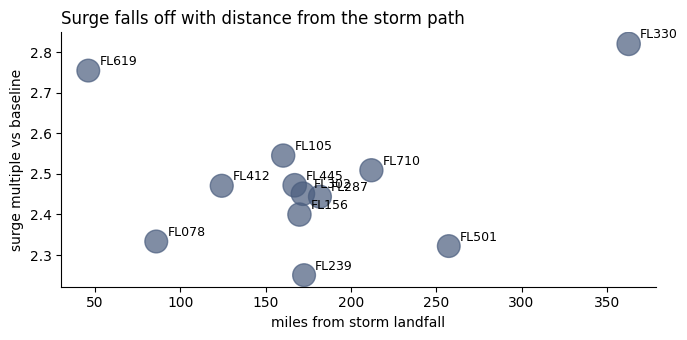

In [41]:
by_store = store_results[["store_id","surge_multiple","miles_from_landfall","total_transactions"]]

fig, ax = plt.subplots(figsize=(7, 3.5))
sizes = by_store['total_transactions'] / 15
ax.scatter(by_store['miles_from_landfall'], by_store['surge_multiple'],
           s=sizes, alpha=0.7, color='#4a5d7e')
for row in by_store.itertuples():
    ax.annotate(row.store_id, (row.miles_from_landfall, row.surge_multiple),
                textcoords='offset points', xytext=(8, 4), fontsize=9)
ax.set_title('Surge falls off with distance from the storm path',
             loc='left', fontsize=12)
ax.set_xlabel('miles from storm landfall')
ax.set_ylabel('surge multiple vs baseline')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

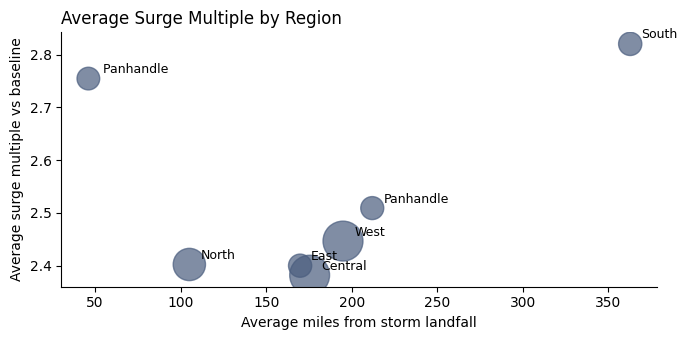

In [46]:
# Group stores by region
by_region = (
    store_results.groupby("region")
    .agg(
        surge_multiple=("surge_multiple", "mean"),
        miles_from_landfall=("miles_from_landfall", "mean"),
        total_transactions=("total_transactions", "sum")
    )
    .reset_index()
)

# Create scatter plot
fig, ax = plt.subplots(figsize=(7, 3.5))

sizes = by_region["total_transactions"] / 15

ax.scatter(
    by_region["miles_from_landfall"],
    by_region["surge_multiple"],
    s=sizes,
    alpha=0.7,
    color="#4a5d7e"
)

# Label each region
for row in by_region.itertuples():
    ax.annotate(
        row.region,
        (row.miles_from_landfall, row.surge_multiple),
        textcoords="offset points",
        xytext=(8, 4),
        fontsize=9
    )

ax.set_title("Average Surge Multiple by Region",
             loc="left", fontsize=12)
ax.set_xlabel("Average miles from storm landfall")
ax.set_ylabel("Average surge multiple vs baseline")

for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1492/668343179.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


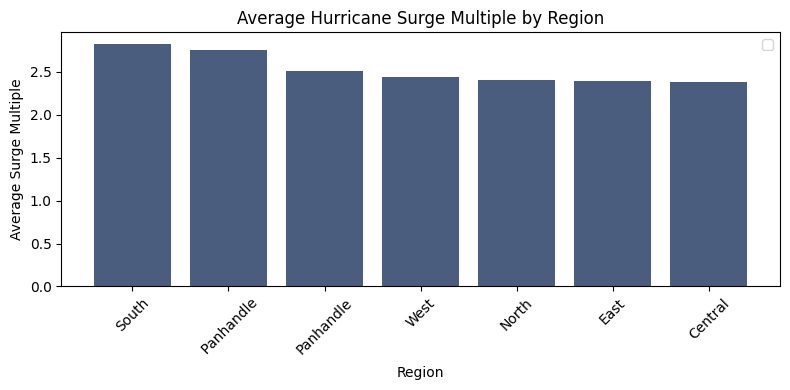

In [45]:
import matplotlib.pyplot as plt

# Calculate average surge multiple by region
region_surge = (
    store_results.groupby("region")["surge_multiple"]
    .mean()
    .reset_index()
    .sort_values("surge_multiple", ascending=False)
)

# Create bar chart
plt.figure(figsize=(8, 4))

plt.bar(
    region_surge["region"],
    region_surge["surge_multiple"],
    color="#4a5d7e"
)

plt.title("Average Hurricane Surge Multiple by Region")
plt.xlabel("Region")
plt.ylabel("Average Surge Multiple")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()